# 🗽 MTA Daily Ridership Analysis & Machine Learning Forecasting

---

### 1. 📌 Project Overview & Scope

#### Project Overview
This notebook contains a predictive analytics pipeline to analyze MTA daily transit ridership and forecast demand for the next 30 days using Python and Scikit-Learn.

#### Target Metrics (7 Transit Sectors)
1. **Subways_Ridership**
2. **Buses_Ridership**
3. **LIRR_Ridership**
4. **MetroNorth_Ridership**
5. **AccessARide_Trips**
6. **Bridges_and_Tunnels_Traffic**
7. **Staten_Island_Railway_Ridership**

#### Notebook Scope
* **Data Cleaning:** Parse dates and standardize column names into clean `snake_case` labels.
* **Feature Engineering:** Extract temporal parameters (`Year`, `Month`, `Day`, `IsWeekend`).
* **Forecasting:** Train 7 independent `RandomForestRegressor` models for future 30-day projection.
* **Local Export:** Save results locally as a standardized CSV file.

## 🧹 Section 1: Data Cleaning & Feature Engineering

### 1. Column Standardization
We convert raw column names into a standardized `snake_case` format by removing colons, spaces, and percentages (e.g., standardizing `Subways: Total Estimated Ridership` to `Subways_Ridership`).

### 2. Data Quality Checks
* **Date Parsing:** Converted the `Date` column to `datetime64` format.
* **Missing Values:** Verified there are **0 missing values**.
* **Duplicates:** Verified there are **0 duplicate rows**.

### 3. Feature Extraction
We extract calendar features to use as inputs for the machine learning models:
* `Year`, `Month`, `Day`
* `IsWeekend` (1 for Saturday/Sunday, 0 for weekdays)

In [6]:
import pandas as pd

# Load the raw dataset
df = pd.read_csv('MTA_Daily_Ridership.csv')

# Convert the Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# View dataset shape
print("Data loaded successfully! Shape:", df.shape)
df.head()

Data loaded successfully! Shape: (1706, 15)


,Date,Subways: Total Estimated Ridership,Subways: % of Comparable Pre-Pandemic Day,Buses: Total Estimated Ridership,Buses: % of Comparable Pre-Pandemic Day,LIRR: Total Estimated Ridership,LIRR: % of Comparable Pre-Pandemic Day,Metro-North: Total Estimated Ridership,Metro-North: % of Comparable Pre-Pandemic Day,Access-A-Ride: Total Scheduled Trips,Access-A-Ride: % of Comparable Pre-Pandemic Day,Bridges and Tunnels: Total Traffic,Bridges and Tunnels: % of Comparable Pre-Pandemic Day,Staten Island Railway: Total Estimated Ridership,Staten Island Railway: % of Comparable Pre-Pandemic Day
0,2020-03-01,2212965,97,984908,99,86790,100,55825,59,19922,113,786960,98,1636,52
1,2020-03-02,5329915,96,2209066,99,321569,103,180701,66,30338,102,874619,95,17140,107
2,2020-03-03,5481103,98,2228608,99,319727,102,190648,69,32767,110,882175,96,17453,109
3,2020-03-04,5498809,99,2177165,97,311662,99,192689,70,34297,115,905558,98,17136,107
4,2020-03-05,5496453,99,2244515,100,307597,98,194386,70,33209,112,929298,101,17203,108


In [8]:
# Check dimensions, missing values, and duplicates
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Rows:", df.duplicated().sum())
df

Dataset Shape: (1706, 15)
Total Missing Values: 0
Total Duplicate Rows: 0


,Date,Subways: Total Estimated Ridership,Subways: % of Comparable Pre-Pandemic Day,Buses: Total Estimated Ridership,Buses: % of Comparable Pre-Pandemic Day,LIRR: Total Estimated Ridership,LIRR: % of Comparable Pre-Pandemic Day,Metro-North: Total Estimated Ridership,Metro-North: % of Comparable Pre-Pandemic Day,Access-A-Ride: Total Scheduled Trips,Access-A-Ride: % of Comparable Pre-Pandemic Day,Bridges and Tunnels: Total Traffic,Bridges and Tunnels: % of Comparable Pre-Pandemic Day,Staten Island Railway: Total Estimated Ridership,Staten Island Railway: % of Comparable Pre-Pandemic Day
0,2020-03-01,2212965,97,984908,99,86790,100,55825,59,19922,113,786960,98,1636,52
1,2020-03-02,5329915,96,2209066,99,321569,103,180701,66,30338,102,874619,95,17140,107
2,2020-03-03,5481103,98,2228608,99,319727,102,190648,69,32767,110,882175,96,17453,109
3,2020-03-04,5498809,99,2177165,97,311662,99,192689,70,34297,115,905558,98,17136,107
4,2020-03-05,5496453,99,2244515,100,307597,98,194386,70,33209,112,929298,101,17203,108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1701,2024-10-27,2215973,90,737246,74,120849,133,115917,110,23888,130,918610,109,2568,68
1702,2024-10-28,3985381,69,1460653,65,253923,81,229873,79,35666,120,926409,100,7829,44
1703,2024-10-29,4391065,76,1528993,68,272526,87,249585,86,38621,130,939734,101,8867,50
1704,2024-10-30,4450028,77,1553250,69,267007,85,246035,85,40468,136,970092,105,8843,50


In [9]:
# Convert Date to datetime format and sort chronologically
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Standardize column names into SQL-friendly format
clean_columns = [
    c.replace(': Total Estimated Ridership', '_Ridership')
     .replace(': Total Scheduled Trips', '_Trips')
     .replace(': Total Traffic', '_Traffic')
     .replace(': % of Comparable Pre-Pandemic Day', '_PrePandemicPct')
     .replace(' ', '_')
     .replace('-', '')
     .replace('__', '_')
    for c in df.columns
]

df.columns = clean_columns
print("Cleaned Column Names:")
print(df.columns.tolist())

Cleaned Column Names:
['Date', 'Subways_Ridership', 'Subways_PrePandemicPct', 'Buses_Ridership', 'Buses_PrePandemicPct', 'LIRR_Ridership', 'LIRR_PrePandemicPct', 'MetroNorth_Ridership', 'MetroNorth_PrePandemicPct', 'AccessARide_Trips', 'AccessARide_PrePandemicPct', 'Bridges_and_Tunnels_Traffic', 'Bridges_and_Tunnels_PrePandemicPct', 'Staten_Island_Railway_Ridership', 'Staten_Island_Railway_PrePandemicPct']


In [10]:
# Extract calendar features for analysis and machine learning models
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['MonthName'] = df['Date'].dt.strftime('%B')
df['Day'] = df['Date'].dt.day
df['DayOfWeek'] = df['Date'].dt.strftime('%A')
df['IsWeekend'] = df['Date'].dt.dayofweek.isin([5, 6]).astype(int)

df.head(3)

,Date,Subways_Ridership,Subways_PrePandemicPct,Buses_Ridership,Buses_PrePandemicPct,LIRR_Ridership,LIRR_PrePandemicPct,MetroNorth_Ridership,MetroNorth_PrePandemicPct,AccessARide_Trips,...,Bridges_and_Tunnels_Traffic,Bridges_and_Tunnels_PrePandemicPct,Staten_Island_Railway_Ridership,Staten_Island_Railway_PrePandemicPct,Year,Month,MonthName,Day,DayOfWeek,IsWeekend
0,2020-03-01,2212965,97,984908,99,86790,100,55825,59,19922,...,786960,98,1636,52,2020,3,March,1,Sunday,1
1,2020-03-02,5329915,96,2209066,99,321569,103,180701,66,30338,...,874619,95,17140,107,2020,3,March,2,Monday,0
2,2020-03-03,5481103,98,2228608,99,319727,102,190648,69,32767,...,882175,96,17453,109,2020,3,March,3,Tuesday,0


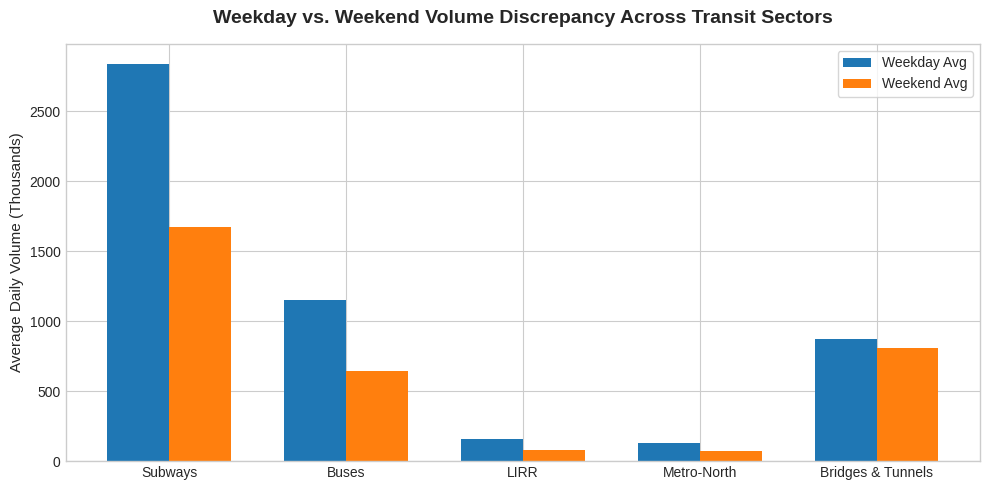

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Select key agencies for comparison
agencies = [
    ('Subways', 'Subways_Ridership'),
    ('Buses', 'Buses_Ridership'),
    ('LIRR', 'LIRR_Ridership'),
    ('Metro-North', 'MetroNorth_Ridership'),
    ('Bridges & Tunnels', 'Bridges_and_Tunnels_Traffic')
]

weekday_means = [df[df['IsWeekend'] == 0][col].mean() / 1e3 for _, col in agencies]
weekend_means = [df[df['IsWeekend'] == 1][col].mean() / 1e3 for _, col in agencies]
labels = [name for name, _ in agencies]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, weekday_means, width, label='Weekday Avg', color='#1f77b4')
rects2 = ax.bar(x + width/2, weekend_means, width, label='Weekend Avg', color='#ff7f0e')

ax.set_ylabel('Average Daily Volume (Thousands)', fontsize=11)
ax.set_title('Weekday vs. Weekend Volume Discrepancy Across Transit Sectors', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

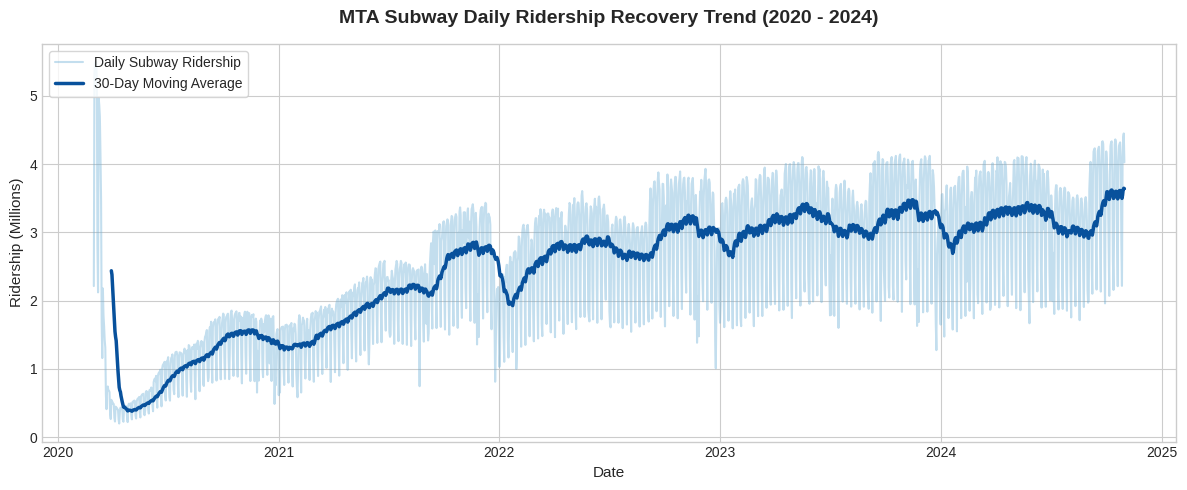

In [17]:
# Set visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(12, 5))

# Plot raw daily values and 30-day moving average
ax.plot(df['Date'], df['Subways_Ridership'] / 1e6, label='Daily Subway Ridership', color='#6baed6', alpha=0.4)
ax.plot(df['Date'], df['Subways_Ridership'].rolling(30).mean() / 1e6, label='30-Day Moving Average', color='#08519c', linewidth=2.5)

ax.set_title('MTA Subway Daily Ridership Recovery Trend (2020 - 2024)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('Ridership (Millions)', fontsize=11)
ax.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
plt.show()

In [11]:
# Export the single cleaned dataset to be loaded into SQL Server
df.to_csv('MTA_Daily_Ridership_Cleaned.csv', index=False)
print("Successfully exported cleaned dataset: MTA_Daily_Ridership_Cleaned.csv")

Successfully exported cleaned dataset: MTA_Daily_Ridership_Cleaned.csv


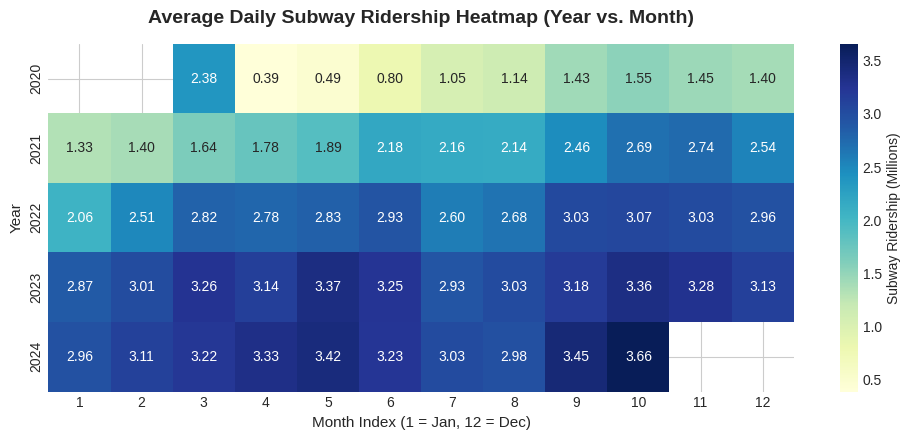

In [19]:
# Create Year vs Month pivot table
pivot_table = df.pivot_table(values='Subways_Ridership', index='Year', columns='Month', aggfunc='mean') / 1e6

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Subway Ridership (Millions)'}, ax=ax)

ax.set_title('Average Daily Subway Ridership Heatmap (Year vs. Month)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month Index (1 = Jan, 12 = Dec)', fontsize=11)
ax.set_ylabel('Year', fontsize=11)
plt.tight_layout()
plt.show()

## 🤖 Section 2: Machine Learning Methodology

### 1. Model Selection
We train **7 independent Random Forest Regressor models** (one for each transit agency) to capture their unique travel patterns.

### 2. Features and Targets
* **Input Features:** `Year`, `Month`, `Day`, `IsWeekend`
* **Target Variables:** The 7 transit ridership and traffic metrics.

### 3. Setup & Execution
* **Estimators:** `n_estimators=100` (100 decision trees to average predictions).
* **Reproducibility:** `random_state=42` to ensure consistent outputs.
* **Process:** Each model is fitted using `.fit(X_train, y_train)` and used to project demand 30 days ahead using `.predict(X_future)`.

In [12]:
import pandas as pd
import numpy as np
# Import Random Forest Regressor model from Scikit-Learn
from sklearn.ensemble import RandomForestRegressor

# Load the cleaned MTA dataset generated from the cleaning phase
df = pd.read_csv('MTA_Daily_Ridership_Cleaned.csv')

# Ensure Date column is in datetime format for accurate date arithmetic
df['Date'] = pd.to_datetime(df['Date'])

print("Cleaned dataset successfully loaded for Machine Learning!")
print("Last date in dataset:", df['Date'].max())

Cleaned dataset successfully loaded for Machine Learning!
Last date in dataset: 2024-10-31 00:00:00


In [13]:
# 1. Input Features (X): The numeric calendar attributes used to train the model
# We use Year, Month, Day, and IsWeekend because transit demand follows strong calendar patterns
features = ['Year', 'Month', 'Day', 'IsWeekend']

# 2. Target Variables (y): The 7 agency ridership columns we want to predict
target_cols = [
    'Subways_Ridership',
    'Buses_Ridership',
    'LIRR_Ridership',
    'MetroNorth_Ridership',
    'AccessARide_Trips',
    'Bridges_and_Tunnels_Traffic',
    'Staten_Island_Railway_Ridership'
]

print("Features (Inputs):", features)
print("Target Agencies (Outputs):", target_cols)

Features (Inputs): ['Year', 'Month', 'Day', 'IsWeekend']
Target Agencies (Outputs): ['Subways_Ridership', 'Buses_Ridership', 'LIRR_Ridership', 'MetroNorth_Ridership', 'AccessARide_Trips', 'Bridges_and_Tunnels_Traffic', 'Staten_Island_Railway_Ridership']


In [14]:
# Find the latest available date in the dataset (October 31, 2024)
last_date = df['Date'].max()

# Create a sequence of 30 future dates starting from the day after last_date
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=30)

# Build a new DataFrame to hold the future feature values
future_df = pd.DataFrame({'Date': future_dates})

# Extract the exact same temporal features (Year, Month, Day, IsWeekend) for future dates
future_df['Year'] = future_df['Date'].dt.year
future_df['Month'] = future_df['Date'].dt.month
future_df['Day'] = future_df['Date'].dt.day
# Assign 1 for Saturday/Sunday (weekend), 0 for weekdays
future_df['IsWeekend'] = future_df['Date'].dt.dayofweek.isin([5, 6]).astype(int)

future_df.head(5)

,Date,Year,Month,Day,IsWeekend
0,2024-11-01,2024,11,1,0
1,2024-11-02,2024,11,2,1
2,2024-11-03,2024,11,3,1
3,2024-11-04,2024,11,4,0
4,2024-11-05,2024,11,5,0


In [15]:
# Create an empty DataFrame to store the forecasted values alongside future dates
forecast_df = pd.DataFrame({'Date': future_dates})

# Loop through each of the 7 transit agencies to train an independent model for each
for col in target_cols:
    # Set X (training inputs) and y (historical ridership target)
    X_train = df[features]
    y_train = df[col]

    # Initialize Random Forest Regressor:
    # - n_estimators=100: Uses an ensemble of 100 decision trees for high accuracy
    # - random_state=42: Ensures reproducible results every time the code runs
    model = RandomForestRegressor(n_estimators=100, random_state=42)

    # Train the model on historical data
    model.fit(X_train, y_train)

    # Predict ridership for the 30 future days using future features
    X_future = future_df[features]
    predictions = model.predict(X_future)

    # Save rounded integer predictions in forecast_df
    forecast_df[f'Predicted_{col}'] = predictions.astype(int)

print("Forecasting completed for all 7 transit agencies!")
forecast_df.head(5)

Forecasting completed for all 7 transit agencies!


,Date,Predicted_Subways_Ridership,Predicted_Buses_Ridership,Predicted_LIRR_Ridership,Predicted_MetroNorth_Ridership,Predicted_AccessARide_Trips,Predicted_Bridges_and_Tunnels_Traffic,Predicted_Staten_Island_Railway_Ridership
0,2024-11-01,4000638,1387349,240129,211815,36389,934607,7988
1,2024-11-02,2417050,770533,130836,139487,23467,900880,3386
2,2024-11-03,2328859,767592,131035,139142,23462,887340,3421
3,2024-11-04,3681297,1320494,250959,217097,35819,940576,6775
4,2024-11-05,3819128,1360067,253511,216947,35860,928843,6999


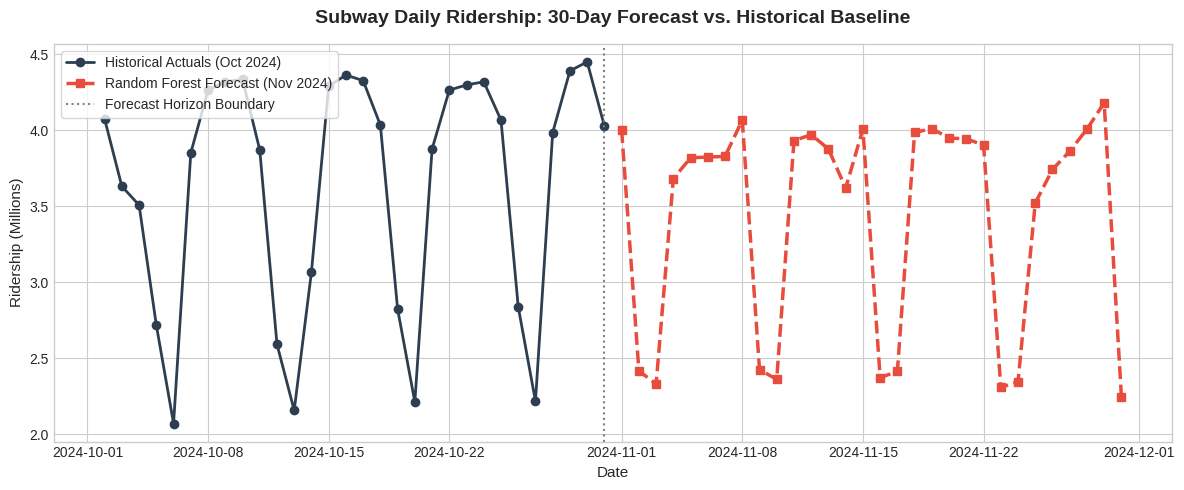

In [22]:
# Extract last 30 historical days and merge with 30-day forecast
recent_historical = df.tail(30)[['Date', 'Subways_Ridership']].copy()
forecast_df['Date'] = pd.to_datetime(forecast_df['Date'])

fig, ax = plt.subplots(figsize=(12, 5))

# Plot historical actuals
ax.plot(recent_historical['Date'], recent_historical['Subways_Ridership'] / 1e6, label='Historical Actuals (Oct 2024)', color='#2c3e50', linewidth=2, marker='o')

# Plot ML forecasted values - corrected to use the prefix 'Predicted_'
ax.plot(forecast_df['Date'], forecast_df['Predicted_Subways_Ridership'] / 1e6, label='Random Forest Forecast (Nov 2024)', color='#e74c3c', linewidth=2.5, linestyle='--', marker='s')

ax.set_title('Subway Daily Ridership: 30-Day Forecast vs. Historical Baseline', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('Ridership (Millions)', fontsize=11)
ax.axvline(x=recent_historical['Date'].max(), color='gray', linestyle=':', label='Forecast Horizon Boundary')
ax.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
plt.show()

## 📊 Section 3: Forecast Outcomes & Analytical Inferences

### 1. 30-Day Forecast Summary Table
The table below contrasts the average predicted daily traffic and ridership volumes for weekdays versus weekends, along with the percentage demand reduction on weekends:

| Transit Metric | Weekday Average | Weekend Average | Weekend Drop (%) |
| :--- | :---: | :---: | :---: |
| **Subways_Ridership** | 3,846,039 | 2,330,832 | -39.4% |
| **Buses_Ridership** | 1,380,830 | 761,962 | -44.8% |
| **LIRR_Ridership** | 248,392 | 131,048 | -47.2% |
| **MetroNorth_Ridership** | 215,901 | 139,129 | -35.6% |
| **AccessARide_Trips** | 35,970 | 23,286 | -35.3% |
| **Bridges_and_Tunnels_Traffic** | 929,486 | 895,945 | -3.6% |
| **Staten_Island_Railway_Ridership** | 7,370 | 3,111 | -57.8% |

### 2. Analytical Findings
* **Mass Transit vs. Private Vehicles:** Mass public transit agencies (Subways, Buses, Commuter Rails) experience massive drops of **35% to 58%** on weekends, highlighting their reliance on traditional weekday commute cycles. In sharp contrast, private vehicular toll traffic (**Bridges & Tunnels**) remains highly stable, showing a minimal **-3.6%** drop on weekends.
* **Paratransit Demand:** Special-service transit (**Access-A-Ride**) exhibits moderate resilience with a **-35.3%** drop, indicating a steadier distribution of essential non-work travel throughout the entire week.

In [16]:
# Save the 30-day forecast table into a CSV file
# This file will be imported into Power BI for visual comparison against historical data
forecast_df.to_csv('MTA_30Day_Forecast.csv', index=False)

print("Forecast exported successfully as 'MTA_30Day_Forecast.csv'!")

Forecast exported successfully as 'MTA_30Day_Forecast.csv'!
